In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

FILE = "Maluku_Utara_Harga_Konstan.xls"
raw = pd.read_excel(FILE, header=None)
df = raw.iloc[4:, :].copy()          # buang 4 baris judul/header laporan (sumber NaN)
df.columns = ['Sektor'] + [str(t) for t in range(2010, 2019)] + ['2019', '2020']
df['Sektor'] = df['Sektor'].str.strip()
for c in df.columns[1:]:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.reset_index(drop=True)
print("Bentuk data:", df.shape, "| NaN pada sel data:", int(df.isna().sum().sum()))
df.head()

Bentuk data: (62, 12) | NaN pada sel data: 0


,Sektor,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,"Pertanian, Kehutanan, dan Perikanan",3.936693e+06,4.105564e+06,4.371355e+06,4.525959e+06,4.662502e+06,4.742546e+06,4.943915e+06,5.100386e+06,5.305882e+06,5.518061e+06,5.593187e+06
1,"Pertanian, Peternakan, Perburuan dan Jasa Pert...",2.509143e+06,2.622894e+06,2.826485e+06,2.944588e+06,3.056677e+06,3.168818e+06,3.309299e+06,3.411405e+06,3.526131e+06,3.629118e+06,3.703222e+06
2,a. Tanaman Pangan,3.465241e+05,3.589684e+05,3.844936e+05,4.093202e+05,4.023965e+05,3.901116e+05,4.071767e+05,4.157285e+05,4.338610e+05,4.383950e+05,4.394329e+05
3,b. Tanaman Hortikultura,1.844041e+05,1.897419e+05,1.977286e+05,2.015346e+05,2.068536e+05,2.113473e+05,2.284364e+05,2.370557e+05,2.539669e+05,2.703675e+05,2.834512e+05
4,c. Tanaman Perkebunan,1.791373e+06,1.876215e+06,2.041015e+06,2.123924e+06,2.225937e+06,2.331307e+06,2.417376e+06,2.483021e+06,2.541078e+06,2.606586e+06,2.669844e+06


In [2]:
induk = ['Pertanian, Kehutanan, dan Perikanan', 'Pertanian, Peternakan, Perburuan dan Jasa Pertanian',
         'Pertambangan dan Penggalian', 'Industri Pengolahan', 'Pengadaan Listrik dan Gas',
         'Perdagangan Besar dan Eceran; Reparasi Mobil dan Sepeda Motor', 'Transportasi dan Pergudangan',
         'Penyediaan Akomodasi dan Makan Minum', 'Jasa Keuangan dan Asuransi', 'NTB Maluku Utara']
leaf = df[~df['Sektor'].isin(induk)].reset_index(drop=True)
print("Jumlah sektor level terbawah:", len(leaf))
print("Validasi: jumlah 2019 =", round(leaf['2019'].sum(), 2), "| total resmi =", round(df.iloc[-1]['2019'], 2))

nol = leaf[(leaf['2019'] == 0) & (leaf['2020'] == 0)]
print("\nSektor bernilai 0 (missing struktural):", len(nol), f"({len(nol)/len(leaf)*100:.1f}%)")
print(nol['Sektor'].tolist())

Jumlah sektor level terbawah: 52
Validasi: jumlah 2019 = 26561305.88 | total resmi = 26561305.88

Sektor bernilai 0 (missing struktural): 8 (15.4%)
['Pertambangan Minyak, Gas dan Panas Bumi', 'Pertambangan Batubara dan Lignit', 'Industri Batubara dan Pengilangan Migas', 'Industri Pengolahan Tembakau', 'Industri Kulit, Barang dari Kulit dan Alas Kaki', 'Industri Karet, Barang dari Karet dan Plastik', 'Industri Mesin dan Perlengkapan', 'Angkutan Rel']


In [3]:
# a) Missing struktural -> hapus (sektor tidak beraktivitas; imputasi akan menciptakan data fiktif)
v = leaf[(leaf['2019'] > 0) & (leaf['2020'] > 0)].copy().reset_index(drop=True)
# b) Skala: Juta Rp -> Miliar Rp
v['X'] = v['2019'] / 1000
v['Y'] = v['2020'] / 1000
v['Growth'] = (v['Y'] - v['X']) / v['X'] * 100
print("Data valid:", len(v))
print(v[['X', 'Y']].describe().round(2))
print("Skewness X :", round(v['X'].skew(), 2))
print("Korelasi X-Y:", round(v['X'].corr(v['Y']), 4))

Data valid: 44
             X        Y
count    44.00    44.00
mean    603.67   633.37
std    1063.67  1101.54
min       0.23     0.24
25%      15.59    15.33
50%     159.64   138.23
75%     622.74   613.89
max    4698.39  4461.28
Skewness X : 2.55
Korelasi X-Y: 0.9823


In [4]:
q1, q3 = v['Growth'].quantile([.25, .75]); iqr = q3 - q1
lb, ub = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  batas=[{lb:.2f}, {ub:.2f}]")
out = v[(v['Growth'] < lb) | (v['Growth'] > ub)]
print(out[['Sektor', 'X', 'Y', 'Growth']].round(2).to_string())

clean = v[v['Sektor'] != 'Industri Logam Dasar'].reset_index(drop=True)
print("\nData bersih:", len(clean), "sektor")

Q1=-4.70  Q3=3.18  IQR=7.88  batas=[-16.52, 15.00]
                                             Sektor       X        Y  Growth
15                             Industri Logam Dasar  902.95  2198.62  143.49
24  Perdagangan Mobil, Sepeda Motor dan Reparasinya  178.55   133.71  -25.11
28          Angkutan Sungai Danau dan Penyeberangan   99.76    71.29  -28.54
29                                   Angkutan Udara  415.35   239.49  -42.34

Data bersih: 43 sektor


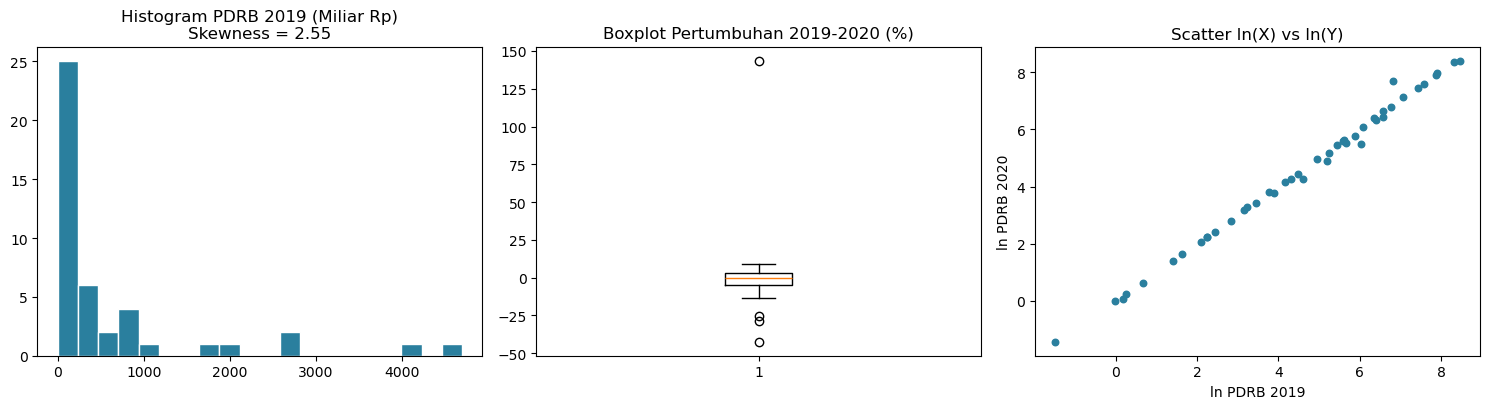

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].hist(v['X'], bins=20, color='#2a7f9e', edgecolor='white')
ax[0].set_title(f"Histogram PDRB 2019 (Miliar Rp)\nSkewness = {v['X'].skew():.2f}")
ax[1].boxplot(v['Growth']); ax[1].set_title('Boxplot Pertumbuhan 2019-2020 (%)')
ax[2].scatter(np.log(v['X']), np.log(v['Y']), s=22, color='#2a7f9e')
ax[2].set_title('Scatter ln(X) vs ln(Y)'); ax[2].set_xlabel('ln PDRB 2019'); ax[2].set_ylabel('ln PDRB 2020')
plt.tight_layout(); plt.show()

In [6]:
idx = list(range(0, 43, 3)) + [43]
smp = v.loc[idx].copy()
smp[['X', 'Y']] = smp[['X', 'Y']].round(2)
smp = smp[smp['Sektor'] != 'Industri Logam Dasar'].reset_index(drop=True)
smp['lnX'] = np.log(smp['X']).round(4)
smp['lnY'] = np.log(smp['Y']).round(4)
print("n sampel:", len(smp))
smp[['Sektor', 'X', 'Y', 'lnX', 'lnY']]

n sampel: 15


,Sektor,X,Y,lnX,lnY
0,a. Tanaman Pangan,438.40,439.43,6.0831,6.0855
1,d. Peternakan,270.03,264.98,5.5985,5.5797
2,Perikanan,1699.46,1710.54,7.4381,7.4446
3,Industri Makanan dan Minuman,354.42,324.66,5.8705,5.7828
4,Industri Kertas dan Barang dari Kertas; Percet...,5.11,5.15,1.6312,1.6390
5,Industri Furnitur,8.16,7.97,2.0992,2.0757
6,Pengadaan Gas dan Produksi Es,1.98,1.90,0.6831,0.6419
7,"Perdagangan Mobil, Sepeda Motor dan Reparasinya",178.55,133.71,5.1849,4.8957
8,Angkutan Laut,287.23,248.60,5.6603,5.5158
9,Pergudangan dan Jasa Penunjang Angkutan; Pos d...,140.73,142.74,4.9468,4.9610


In [7]:
model = LinearRegression().fit(smp[['lnX']], smp['lnY'])
a, b = model.intercept_, model.coef_[0]
print(f"a = {a:.4f}")
print(f"b = {b:.4f}")
print(f"Persamaan: ln(Y) = {a:.4f} + {b:.4f} ln(X)   ->   Y = {np.exp(a):.4f} * X^{b:.4f}")

a = -0.0412
b = 1.0024
Persamaan: ln(Y) = -0.0412 + 1.0024 ln(X)   ->   Y = 0.9596 * X^1.0024


In [8]:
def evaluasi(nama, y, p):
    print(f"{nama:<22} R2={r2_score(y, p):.4f}  MAE={mean_absolute_error(y, p):7.2f}  "
          f"RMSE={np.sqrt(mean_squared_error(y, p)):7.2f}  MAPE={mean_absolute_percentage_error(y, p)*100:6.2f}%")

pred_lat = np.exp(model.predict(smp[['lnX']]))
uji = clean[~clean['Sektor'].isin(smp['Sektor'])].copy()
uji['lnX'] = np.log(uji['X'])
pred_uji = np.exp(model.predict(uji[['lnX']]))

evaluasi("Data latih (n=15)", smp['Y'], pred_lat)
evaluasi("Data uji (n=%d)" % len(uji), uji['Y'], pred_uji)
evaluasi("Baseline Y = X (uji)", uji['Y'], uji['X'])

Data latih (n=15)      R2=0.9934  MAE=  22.91  RMSE=  38.81  MAPE=  6.07%
Data uji (n=28)        R2=0.9949  MAE=  46.04  RMSE=  90.71  MAPE=  8.75%
Baseline Y = X (uji)   R2=0.9958  MAE=  40.81  RMSE=  81.69  MAPE=  8.39%


In [9]:
lin = LinearRegression().fit(smp[['X']], smp['Y'])
p_lin = lin.predict(uji[['X']])
print(f"Linear biasa: a={lin.intercept_:.4f}, b={lin.coef_[0]:.4f}")
evaluasi("Linear biasa (uji)", uji['Y'], p_lin)
print("Jumlah prediksi negatif:", int((p_lin < 0).sum()), "sektor  -> tidak masuk akal untuk PDRB")

Linear biasa: a=-10.6716, b=1.0337
Linear biasa (uji)     R2=0.9951  MAE=  43.00  RMSE=  88.36  MAPE=292.33%
Jumlah prediksi negatif: 7 sektor  -> tidak masuk akal untuk PDRB


In [10]:
x0 = float(clean.loc[clean['Sektor'] == 'Jasa Pendidikan', 'X'].iloc[0])
y0 = float(clean.loc[clean['Sektor'] == 'Jasa Pendidikan', 'Y'].iloc[0])
yhat = float(np.exp(a + b*np.log(x0)))
print(f"Jasa Pendidikan: X={x0:.2f} -> prediksi Y={yhat:.2f} | aktual Y={y0:.2f} | error={abs(y0-yhat)/y0*100:.2f}%")

Jasa Pendidikan: X=867.23 -> prediksi Y=845.64 | aktual Y=881.89 | error=4.11%


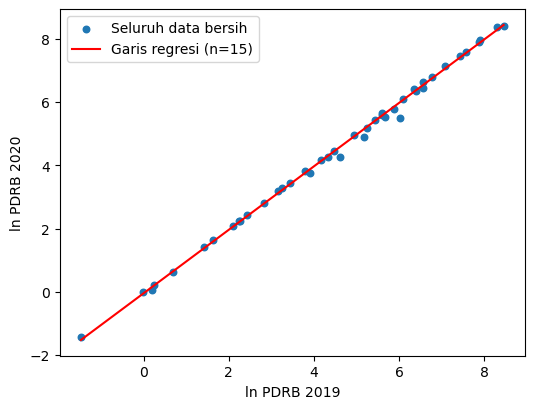

In [11]:
plt.figure(figsize=(6, 4.5))
plt.scatter(np.log(clean['X']), np.log(clean['Y']), s=22, label='Seluruh data bersih')
xx = np.linspace(np.log(clean['X']).min(), np.log(clean['X']).max(), 50)
plt.plot(xx, a + b*xx, color='red', label='Garis regresi (n=15)')
plt.xlabel('ln PDRB 2019'); plt.ylabel('ln PDRB 2020'); plt.legend(); plt.show()